# Supplementary Figure S1. Empirical interpretation of the priority-review tier


In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["rubric", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["RUBRIC", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_rubric.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_RUBRIC_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["rubric_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["rubric_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Datasets and tiers


In [2]:
GOOD_C, ALL_C, POOR_C = BLUE, "0.55", ORANGE
PRIORITY_C, SECONDARY_C = ORANGE, BLUE

def good_poor_split(df):
    good = set(_json("reference/reference_sets/reference_set.json")["pdbs"])
    poor = set(_json("reference/reference_sets/reference_set_poor.json")["pdbs"])
    u = df["pdb_id"].str.upper()
    return df[u.isin(good)], df[u.isin(poor)]

def add_tier(df):
    df = df.copy()
    df["issues"] = df["issues"].apply(lambda d: d if isinstance(d, dict) else {})
    df["tier"] = np.where(df["score"] >= 99.995, "Preferred",
                          np.where(df["score"] >= CUT, "Acceptable", "Review"))
    return df

PAIRS_LW = scored_pairs(lw_only=True)
GOOD, POOR = good_poor_split(PAIRS_LW)
print(f"{len(PAIRS_LW):,} scored pairs | curated {len(GOOD):,} | non-curated {len(POOR):,}")


884,207 scored pairs | curated 371,960 | non-curated 512,247


## Panel A
Score distributions for the curated reference and the non-curated set

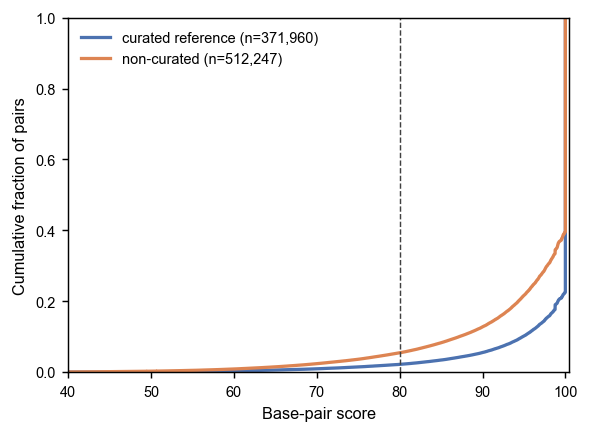

In [3]:
def score_ecdf(ax, groups):
    """Cumulative fraction of each group's pairs at or below every score."""
    for scores, lab, c in groups:
        s = np.sort(scores)
        ax.plot(s, np.arange(1, len(s) + 1) / len(s), label=f"{lab} (n={len(s):,})",
                color=c, lw=1.8)
    ax.axvline(CUT, color="0.25", ls="--", lw=0.8)
    ax.set_xlim(40, 100.5); ax.set_ylim(0, 1)
    ax.set_xlabel("Base-pair score")
    ax.set_ylabel("Cumulative fraction of pairs")
    ax.legend(loc="upper left")
    finish(ax)


def draw_a(ax):
    score_ecdf(ax, ((GOOD["score"].to_numpy(), "curated reference", GOOD_C),
                    (POOR["score"].to_numpy(), "non-curated", POOR_C)))


fig, ax = plt.subplots(figsize=(4.6, 3.4))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS1_A_score_ecdf_by_quality.png")
plt.show()


## Panel B
Base pairs below each cut-off in the curated and non-curated sets, with the fold enrichment

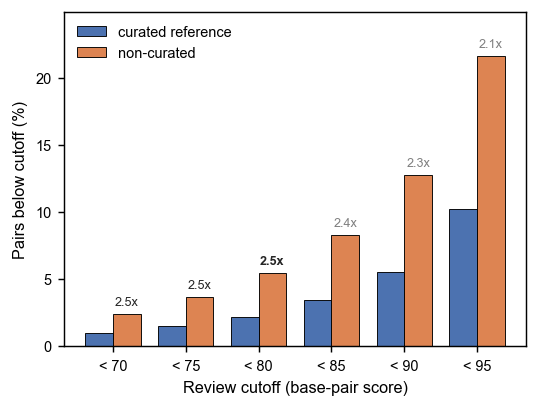

{70: np.float64(2.54), 75: np.float64(2.46), 80: np.float64(2.49), 85: np.float64(2.43), 90: np.float64(2.31), 95: np.float64(2.12)}


In [4]:
CUTS_B = (70, 75, 80, 85, 90, 95)

def draw_b(ax):
    g = np.array([100 * np.mean(GOOD["score"].to_numpy() < c) for c in CUTS_B])
    q = np.array([100 * np.mean(POOR["score"].to_numpy() < c) for c in CUTS_B])
    x = np.arange(len(CUTS_B)); w = 0.38
    ax.bar(x - w / 2, g, w, color=GOOD_C, label="curated reference", edgecolor="black", linewidth=0.5)
    ax.bar(x + w / 2, q, w, color=POOR_C, label="non-curated", edgecolor="black", linewidth=0.5)
    for i, c in enumerate(CUTS_B):
        ax.text(x[i] + w / 2, q[i] + q.max() * 0.02, f"{q[i] / g[i]:.1f}x", ha="center",
                va="bottom", fontsize=7, color="0.15" if c <= CUT else "0.5",
                fontweight="bold" if c == CUT else "normal")
    ax.set_xticks(x, [f"< {c}" for c in CUTS_B])
    ax.set_ylim(0, q.max() * 1.15)
    ax.set_xlabel("Review cutoff (base-pair score)")
    ax.set_ylabel("Pairs below cutoff (%)")
    ax.legend(loc="upper left")
    finish(ax)
    return dict(zip(CUTS_B, q / g))


fig, ax = plt.subplots(figsize=(4.2, 3.2))
enr = draw_b(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS1_B_cutoff_enrichment.png")
plt.show()
print({k: round(v, 2) for k, v in enr.items()})

## Panel C
Enrichment of abnormalities in priority-review relative to secondary-review pairs


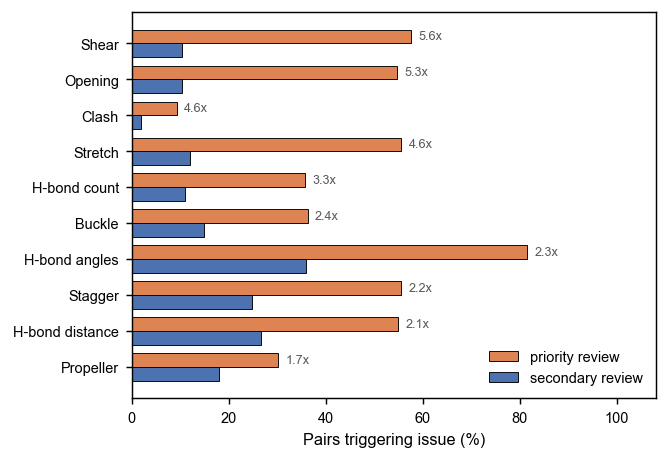

In [5]:
def draw_c(ax):
    df = add_tier(scored_pairs(lw_only=False))
    def freq(sub):
        m = len(sub)
        c = Counter(k for iss in sub["issues"] for k in iss)
        return {k: 100 * c.get(k, 0) / m for k in ISSUES} if m else {k: 0 for k in ISSUES}, m
    fr_r, n_r = freq(df[df.tier == "Review"])
    fr_a, n_a = freq(df[df.tier == "Acceptable"])
    enr = {k: (fr_r[k] / fr_a[k] if fr_a[k] else 0) for k in ISSUES}
    row = sorted(ISSUES, key=lambda k: enr[k])
    y = np.arange(len(row)); h = 0.38
    ax.barh(y + h / 2, [fr_r[k] for k in row], h, color=PRIORITY_C,
            label="priority review", edgecolor="black", linewidth=0.5)
    ax.barh(y - h / 2, [fr_a[k] for k in row], h, color=SECONDARY_C,
            label="secondary review", edgecolor="black", linewidth=0.5)
    for i, k in enumerate(row):
        ax.text(fr_r[k] + 1.5, i + h / 2, f"{enr[k]:.1f}x", va="center", fontsize=7,
                color="0.35")
    ax.set_yticks(y, [ISSUE_LABELS.get(k, k) for k in row])
    ax.set_xlim(0, 108)
    ax.set_xlabel("Pairs triggering issue (%)")
    ax.legend(loc="lower right")
    finish(ax)


fig, ax = plt.subplots(figsize=(5.2, 3.6))
draw_c(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS1_C_issue_prevalence_by_tier.png")
plt.show()


## Panel E
The Figure 4A / E result with the review cut-off at 75, 80 and 85

PDB-REDO  cut 75:  89.6% of 280 units improved [86.1, 92.9]
PDB-REDO  cut 80:  91.1% of 336 units improved [88.1, 93.8]
PDB-REDO  cut 85:  92.2% of 412 units improved [89.3, 94.7]
Better resolution cut 75:  97.7% of 88 units improved [94.3, 100.0]
Better resolution cut 80: 100.0% of 110 units improved [100.0, 100.0]
Better resolution cut 85:  98.4% of 122 units improved [95.9, 100.0]


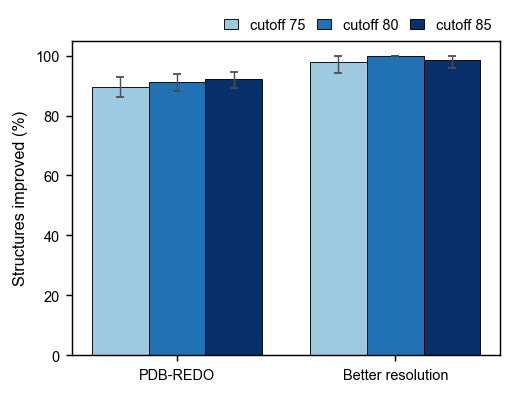

In [6]:
REDO_PAIRS = pd.DataFrame(_json("validation/pdb_redo_pairs_comparison.json")["pairs"])
RES_PAIRS = pd.read_csv(data_file("reference/resolved_again/resolve_pairs_matched.csv"))

CUTS_E = (75, 80, 85)
CUT_SHADES = {75: "#9ecae1", 80: "#2171b5", 85: "#08306b"}
UNITS = {"PDB-REDO": (REDO_PAIRS, ["pdb_id"], "orig_score", "redo_score"),
         "Better resolution": (RES_PAIRS, ["rep", "worst", "best"], "score_w", "score_b")}

def improved_share(df, unit, before, after, cut, n_boot=1000, seed=11):
    f = df[(df[before] < cut) & df[after].notna()]
    u = f.groupby(unit)[[before, after]].mean()
    up = (u[after] > u[before]).to_numpy()
    rng = np.random.default_rng(seed)
    boot = [up[rng.integers(0, len(up), len(up))].mean() for _ in range(n_boot)]
    return 100 * up.mean(), *np.percentile(100 * np.array(boot), [2.5, 97.5]), len(up)

E_STATS = {(c, k): improved_share(df, unit, b, a, k) for c, (df, unit, b, a) in UNITS.items() for k in CUTS_E}
for (c, k), (v, lo, hi, n) in E_STATS.items():
    print(f"{c:9s} cut {k}: {v:5.1f}% of {n} units improved [{lo:.1f}, {hi:.1f}]")

def draw_e(ax):
    groups = list(UNITS)
    x = np.arange(len(groups)); w = 0.26
    for j, k in enumerate(CUTS_E):
        v = np.array([E_STATS[(c, k)][0] for c in groups])
        lo = np.array([E_STATS[(c, k)][1] for c in groups]); hi = np.array([E_STATS[(c, k)][2] for c in groups])
        ax.bar(x + (j - 1) * w, v, w, color=CUT_SHADES[k], label=f"cutoff {k}", edgecolor="black", linewidth=0.5)
        ax.errorbar(x + (j - 1) * w, v, yerr=[v - lo, hi - v], fmt="none", ecolor="0.3",
                    capsize=2, lw=0.8)
    ax.set_xticks(x, groups)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Structures improved (%)")
    ax.legend(loc="lower right", ncol=3, bbox_to_anchor=(1.0, 1.0), handlelength=1.0,
              columnspacing=0.8, borderaxespad=0.2)
    finish(ax)


fig, ax = plt.subplots(figsize=(4.0, 3.1))
draw_e(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS1_D_cutoff_robustness.png")
plt.show()

## Combined figure


text scaled x1.35: 7 pt prints at 7.0 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (8.46 in saved, shown at 6.73 in)


text 7.0 pt, axis titles 8.5 pt, panel letters 12.0 pt at 6.73 in (8.45 in saved)


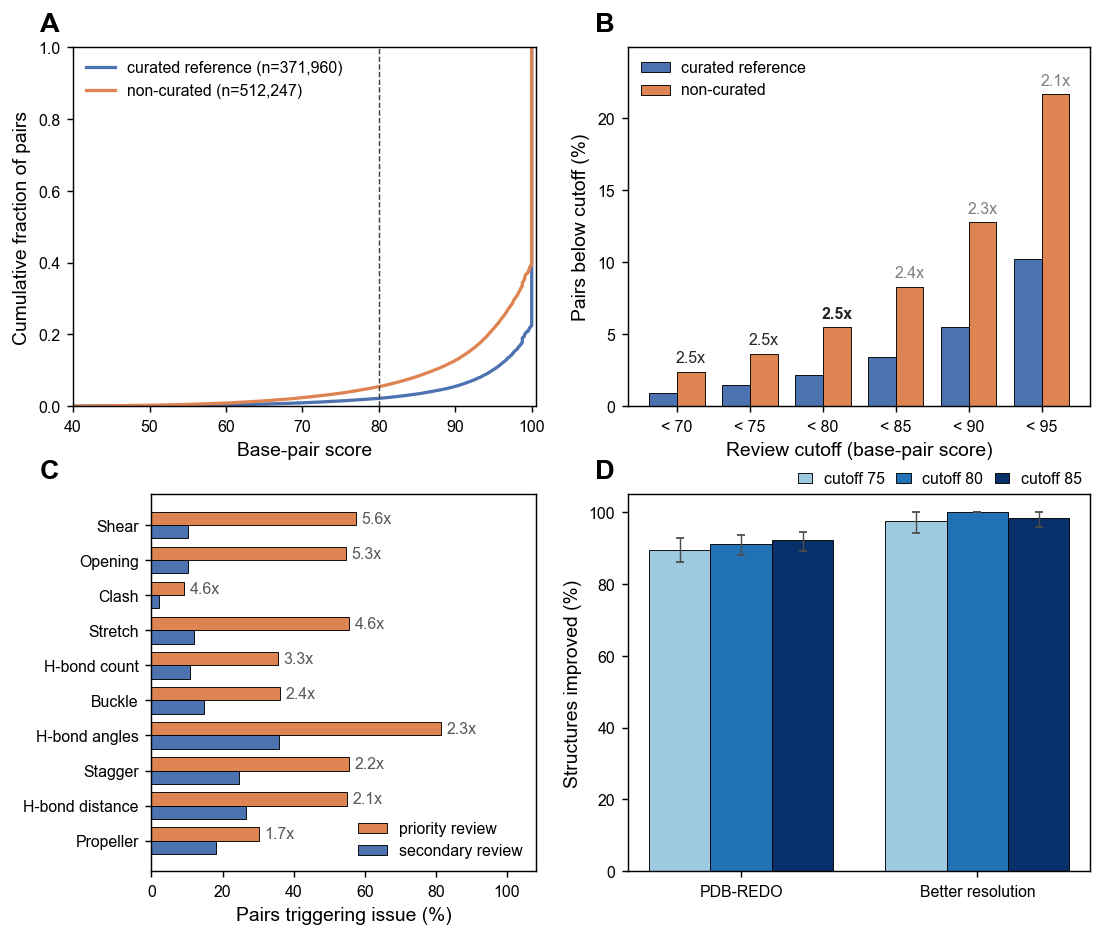

In [7]:
fig = plt.figure(figsize=(8.6, 7.2))
outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.05], hspace=0.24,
                         left=0.075, right=0.985, top=0.95, bottom=0.07)
top = outer[0].subgridspec(1, 2, wspace=0.20)
bottom = outer[1].subgridspec(1, 2, width_ratios=[1.55, 1.0], wspace=0.22)
ax_a = fig.add_subplot(top[0]); ax_b = fig.add_subplot(top[1])
ax_c = fig.add_subplot(bottom[0]); ax_e = fig.add_subplot(bottom[1])
draw_a(ax_a); draw_b(ax_b); draw_c(ax_c); draw_e(ax_e)
for ax, s in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_e, "D")):
    letter(fig, ax, s)
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
enlarge_axis_labels(fig)
for _ax in fig.axes:
    _ax.xaxis.label.set_fontsize(7)
    _ax.yaxis.label.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_inv = fig.transFigure.inverted()
_left = ax_a.get_tightbbox(_r).transformed(_inv).x0
_lab = ax_c.get_position().x0 - ax_c.get_tightbbox(_r).transformed(_inv).x0
_pa, _pb, _pc, _pe = (a.get_position() for a in (ax_a, ax_b, ax_c, ax_e))
_x0 = _left + _lab
ax_c.set_position([_x0, _pc.y0, _pa.x1 - _x0, _pc.height])
ax_e.set_position([_pb.x0, _pe.y0, _pb.width, _pe.height])
_ax_letter = {t.get_text(): t for t in fig.texts}
_ax_letter["C"].set_x(_ax_letter["A"].get_position()[0])
_ax_letter["D"].set_x(_ax_letter["B"].get_position()[0])
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

def _enforce_print_spec(fig, text_pt=7.0, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    """Ticks and other text at text_pt, axis titles at axis_pt, panel letters at letter_pt, as printed at page_in wide."""
    import matplotlib.text as mtext
    axis = {id(lab) for ax in fig.axes for lab in (ax.xaxis.label, ax.yaxis.label)}
    letters = {id(t) for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)}
    texts = [t for t in fig.findobj(mtext.Text) if t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for t in texts:
            t.set_fontsize((letter_pt if id(t) in letters else axis_pt if id(t) in axis else text_pt) * shrink)
    print(f"text {text_pt} pt, axis titles {axis_pt} pt, panel letters {letter_pt} pt at {page_in} in "
          f"({bb.width + 2 * pad:.2f} in saved)")


_enforce_print_spec(fig)
save(fig, "figures/supplemental/figS1.png")
plt.show()
